In [4]:
import pandas as pd
E = pd.read_parquet('data/processed/electricity.parquet')
print(E.columns)

Index(['time', 'consumption', 'generation', 'price_tl', 'temperature',
       'feels_like', 'humidity', 'cloud', 'wind', 'rain', 'holiday', 'year',
       'month', 'hour', 'dow', 'weekend'],
      dtype='object')


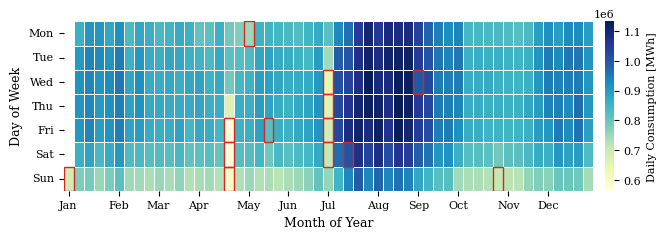

In [26]:
import matplotlib as mpl
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ==========================================================
# 1. Cấu hình Matplotlib chuẩn bài báo khoa học (LaTeX/PDF)
# ==========================================================
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["font.family"] = "serif"
mpl.rcParams["font.size"] = 8

# ==========================================================
# 2. Xử lý và tính toán dữ liệu
# ==========================================================
df_2023 = E[E["year"] == 2023].copy()

# Tính tổng tiêu thụ hàng ngày và xác định ngày đó có phải là ngày lễ hay không
daily_df = (
    df_2023.groupby(df_2023["time"].dt.date)
    .agg(
        daily_consumption=("consumption", "sum"),
        is_holiday=("holiday", "max"),  # 1 nếu có giờ là lễ, 0 nếu không
    )
    .reset_index()
)
daily_df["time"] = pd.to_datetime(daily_df["time"])

# Tính chỉ số tuần và thứ trong tuần
first_day = pd.Timestamp("2023-01-01")
daily_df["week_idx"] = (
    (daily_df["time"] - first_day).dt.days + first_day.weekday()
) // 7
daily_df["dow"] = daily_df["time"].dt.weekday  # 0: Mon, ..., 6: Sun

# Tạo pivot table dữ liệu tiêu thụ
heatmap_matrix = daily_df.pivot(
    index="dow", columns="week_idx", values="daily_consumption"
)

all_weeks = np.arange(heatmap_matrix.columns.max() + 1)
heatmap_matrix = heatmap_matrix.reindex(index=range(7), columns=all_weeks)

# ==========================================================
# 3. Vẽ Heatmap
# ==========================================================
fig, ax = plt.subplots(figsize=(7.16, 2.2))

sns.heatmap(
    heatmap_matrix,
    cmap="YlGnBu",
    cbar_kws={
        "label": "Daily Consumption [MWh]",
        "pad": 0.02,
        "fraction": 0.025,
        "aspect": 18,
    },
    linewidths=0.5,
    linecolor="white",
    ax=ax,
)

# ==========================================================
# 4. Khoanh viền các ô là ngày lễ (Holiday)
# ==========================================================
# Lọc ra danh sách các ngày lễ trong năm 2023
holidays = daily_df[daily_df["is_holiday"] == 1]

for _, row in holidays.iterrows():
    # Tọa độ trong heatmap: x tương ứng week_idx, y tương ứng dow
    x = row["week_idx"]
    y = row["dow"]
    
    # Vẽ viền hình chữ nhật bao quanh ô ngày lễ
    rect = patches.Rectangle(
        (x, y),
        1,
        1,
        linewidth=1,
        edgecolor="#D62728",  # Viền đỏ nổi bật
        facecolor="none",
        zorder=5,
    )
    ax.add_patch(rect)

# ==========================================================
# 5. Tinh chỉnh trục & Nhãn chuẩn tiếng Anh học thuật
# ==========================================================
ax.set_yticks(np.arange(7) + 0.5)
ax.set_yticklabels(
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
    rotation=0,
    fontsize=8,
)
ax.set_ylabel("Day of Week", fontsize=9)

month_first_days = pd.date_range("2023-01-01", "2023-12-01", freq="MS")
month_week_positions = [
    ((d - first_day).days + first_day.weekday()) // 7
    for d in month_first_days
]
month_labels = [d.strftime("%b") for d in month_first_days]

ax.set_xticks([w + 0.5 for w in month_week_positions])
ax.set_xticklabels(month_labels, rotation=0, fontsize=8)
ax.set_xlabel("Month of Year", fontsize=9)

# ==========================================================
# 6. Xuất file PDF vector tối ưu lề cho LaTeX
# ==========================================================
plt.savefig(
    "heatmap_consumption_holidays_2023.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.02,
)
plt.show()
plt.close(fig)

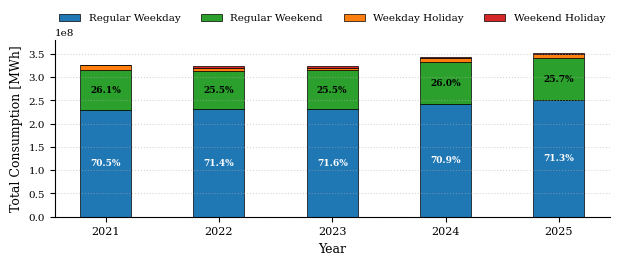

In [11]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ==========================================================
# 1. Cấu hình Matplotlib chuẩn bài báo khoa học (LaTeX/PDF)
# ==========================================================
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["font.family"] = "serif"
mpl.rcParams["font.size"] = 8

# ==========================================================
# 2. Xử lý dữ liệu & Tính tổng tiêu thụ theo 4 loại ngày
# ==========================================================
years = [2021, 2022, 2023, 2024, 2025]
df_sub = E[E["year"].isin(years)].copy()

# Hàm phân loại 4 nhóm ngày
def classify_day_type(row):
    if row["holiday"] == 1 and row["weekend"] == 1:
        return "Weekend Holiday"
    elif row["holiday"] == 1 and row["weekend"] == 0:
        return "Weekday Holiday"
    elif row["holiday"] == 0 and row["weekend"] == 1:
        return "Regular Weekend"
    else:
        return "Regular Weekday"

df_sub["day_type"] = df_sub.apply(classify_day_type, axis=1)

day_types = [
    "Regular Weekday",
    "Regular Weekend",
    "Weekday Holiday",
    "Weekend Holiday",
]

palette = {
    "Regular Weekday": "#1f77b4",  # Xanh dương
    "Regular Weekend": "#2ca02c",  # Xanh lá
    "Weekday Holiday": "#ff7f0e",  # Cam
    "Weekend Holiday": "#d62728",  # Đỏ
}

# Tổng hợp sản lượng tiêu thụ điện (consumption) theo từng năm và loại ngày
agg_df = (
    df_sub.groupby(["year", "day_type"])["consumption"]
    .sum()
    .reset_index()
)

# Chuyển đổi thành ma trận pivot: Dòng là Năm, Cột là 4 loại ngày
pivot_df = agg_df.pivot(index="year", columns="day_type", values="consumption").fillna(0)
pivot_df = pivot_df.reindex(index=years, columns=day_types)

# ==========================================================
# 3. Vẽ biểu đồ cột chồng với tỷ lệ ngang dẹt (Panoramic Ratio)
# ==========================================================
# Kích thước: Ngang 7.16 in (chuẩn 2 cột), Cao 2.3 in (~ tỷ lệ 3.1 : 1)
fig, ax = plt.subplots(figsize=(7.16, 2.3))

x = np.arange(len(years))
width = 0.45  # Độ rộng cột cân đối
bottom = np.zeros(len(years))

for dt in day_types:
    values = pivot_df[dt].values
    bars = ax.bar(
        x,
        values,
        bottom=bottom,
        width=width,
        label=dt,
        color=palette[dt],
        edgecolor="black",
        linewidth=0.5,
    )

    # Hiển thị tỷ lệ đóng góp (%) trực tiếp vào các phần cột đủ lớn
    for i, val in enumerate(values):
        total_year = pivot_df.iloc[i].sum()
        pct = (val / total_year) * 100
        # Chỉ vẽ nhãn nếu tỷ lệ >= 4% để tránh bị dính chữ
        if pct >= 4.0:
            y_pos = bottom[i] + val / 2
            ax.text(
                x[i],
                y_pos,
                f"{pct:.1f}%",
                ha="center",
                va="center",
                color="white" if dt in ["Regular Weekday", "Weekend Holiday"] else "black",
                fontsize=6.5,
                weight="bold",
            )

    bottom += values

# ==========================================================
# 4. Tinh chỉnh trục & Nhãn (Font size chuẩn 6.5 - 9 pt)
# ==========================================================
ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=8)
ax.set_xlabel("Year", fontsize=9)
ax.set_ylabel("Total Consumption [MWh]", fontsize=9)
ax.tick_params(axis="y", labelsize=7.5)

# Đặt định dạng hiển thị trục Y theo ký hiệu khoa học gọn gàng
ax.yaxis.get_offset_text().set_fontsize(7.5)

# Mở rộng nhẹ đỉnh trục tung để không bị cấn sát viền
ax.set_ylim(0, bottom.max() * 1.08)

sns.despine(ax=ax)
ax.grid(axis="y", linestyle=":", alpha=0.5)

# Bố trí Legend dạng hàng ngang sát trên đỉnh
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.20),
    ncol=4,
    frameon=False,
    fontsize=7.5,
)

# ==========================================================
# 5. Xuất file PDF vector tối ưu lề cho LaTeX
# ==========================================================
plt.savefig(
    "stacked_barchart_consumption_daytypes_5years.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.02,
)

plt.show()

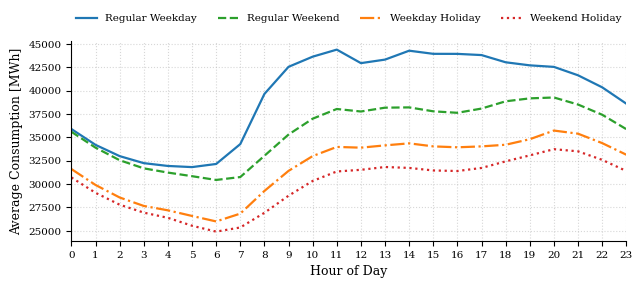

In [12]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ==========================================================
# 1. Cấu hình Matplotlib chuẩn bài báo khoa học (LaTeX/PDF)
# ==========================================================
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["font.family"] = "serif"
mpl.rcParams["font.size"] = 8  # Base font size: 8 pt

# ==========================================================
# 2. Xử lý dữ liệu & Phân loại 4 nhóm ngày
# ==========================================================
years = [2021, 2022, 2023, 2024, 2025]
df_plot = E[E["year"].isin(years)].copy()

# Hàm gán nhãn 4 loại ngày
def classify_day_type(row):
    if row["holiday"] == 1 and row["weekend"] == 1:
        return "Weekend Holiday"
    elif row["holiday"] == 1 and row["weekend"] == 0:
        return "Weekday Holiday"
    elif row["holiday"] == 0 and row["weekend"] == 1:
        return "Regular Weekend"
    else:
        return "Regular Weekday"

df_plot["day_type"] = df_plot.apply(classify_day_type, axis=1)

# Thứ tự nhóm ngày, màu sắc và kiểu nét vẽ nhất quán
day_types = [
    "Regular Weekday",
    "Regular Weekend",
    "Weekday Holiday",
    "Weekend Holiday",
]

palette = {
    "Regular Weekday": "#1f77b4",  # Xanh dương
    "Regular Weekend": "#2ca02c",  # Xanh lá cây
    "Weekday Holiday": "#ff7f0e",  # Cam
    "Weekend Holiday": "#d62728",  # Đỏ
}

style_dict = {
    "Regular Weekday": "-",
    "Regular Weekend": "--",
    "Weekday Holiday": "-.",
    "Weekend Holiday": ":",
}

# Tính giá trị trung bình theo từng giờ cho 4 nhóm ngày
hourly_avg = (
    df_plot.groupby(["day_type", "hour"])["consumption"]
    .mean()
    .reset_index()
)

# ==========================================================
# 3. Vẽ biểu đồ 1 khung nhìn (Panoramic Single Plot)
# ==========================================================
# Chiều ngang 7.16 inch (chuẩn 2 cột LaTeX), chiều cao 2.6 inch
fig, ax = plt.subplots(figsize=(7.16, 2.6))

for dt in day_types:
    dt_data = hourly_avg[hourly_avg["day_type"] == dt]
    if not dt_data.empty:
        ax.plot(
            dt_data["hour"],
            dt_data["consumption"],
            label=dt,
            color=palette[dt],
            linestyle=style_dict[dt],
            linewidth=1.6,
        )

# ==========================================================
# 4. Tinh chỉnh trục & Nhãn (Font size chuẩn 6.5 - 9 pt)
# ==========================================================
ax.set_xlim(0, 23)
ax.set_xticks(range(0, 24, 1))  # Hiển thị đủ 24 giờ
ax.set_xticklabels(range(0, 24, 1), fontsize=7.5)
ax.set_xlabel("Hour of Day", fontsize=9)

ax.set_ylabel("Average Consumption [MWh]", fontsize=9)
ax.tick_params(axis="y", labelsize=7.5)
ax.yaxis.get_offset_text().set_fontsize(7.5)

# Lược bỏ viền trên và bên phải
sns.despine(ax=ax)
ax.grid(True, linestyle=":", alpha=0.5)

# Bố trí Legend dạng hàng ngang sát trên đỉnh
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.18),
    ncol=4,
    frameon=False,
    fontsize=7.5,
)

# ==========================================================
# 5. Xuất file PDF vector tối ưu lề cho LaTeX
# ==========================================================
plt.savefig(
    "lineplot_hourly_consumption_4_daytypes_single.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.02,
)

plt.show()

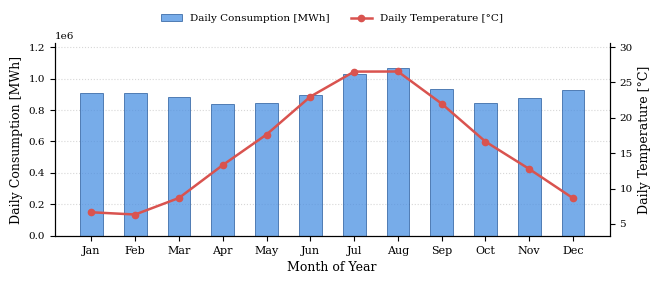

In [14]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ==========================================================
# 1. Cấu hình Matplotlib chuẩn bài báo khoa học (LaTeX/PDF)
# ==========================================================
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["font.family"] = "serif"
mpl.rcParams["font.size"] = 8  # Base font size: 8 pt
mpl.rcParams["text.color"] = "black"
mpl.rcParams["axes.labelcolor"] = "black"
mpl.rcParams["xtick.color"] = "black"
mpl.rcParams["ytick.color"] = "black"

# ==========================================================
# 2. Xử lý dữ liệu đa năm (2021 - 2025)
# ==========================================================
years = [2021, 2022, 2023, 2024, 2025]
df_sub = E[E["year"].isin(years)].copy()

# Bước 1: Tính tổng tiêu thụ và trung bình nhiệt độ theo ngày
daily_df = (
    df_sub.groupby([df_sub["time"].dt.date, "month"])
    .agg(
        daily_consumption=("consumption", "sum"),
        daily_temp=("temperature", "mean"),
    )
    .reset_index()
)

# Bước 2: Tính giá trị trung bình ngày theo từng tháng (12 tháng)
monthly_summary = (
    daily_df.groupby("month")
    .agg(
        avg_daily_consumption=("daily_consumption", "mean"),
        avg_daily_temp=("daily_temp", "mean"),
    )
    .reset_index()
)

month_labels = [
    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "May",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Oct",
    "Nov",
    "Dec",
]

# ==========================================================
# 3. Vẽ biểu đồ song trục (Dual-Axis Plot)
# ==========================================================
# Khổ chuẩn bài báo 2 cột: ngang 7.16 in, cao 2.5 in
fig, ax1 = plt.subplots(figsize=(7.16, 2.5))

x = np.arange(1, 13)
width = 0.52

# Trục Y1 (Trái): Cột biểu diễn Daily Consumption
color_bar = "#4A90E2"
bars = ax1.bar(
    x,
    monthly_summary["avg_daily_consumption"],
    width=width,
    color=color_bar,
    alpha=0.75,
    edgecolor="#2C5E9E",
    linewidth=0.7,
    label="Daily Consumption [MWh]",
    zorder=2,
)

ax1.set_xlabel("Month of Year", fontsize=9, color="black")
ax1.set_ylabel("Daily Consumption [MWh]", fontsize=9, color="black")
ax1.tick_params(axis="y", labelcolor="black", labelsize=7.5)
ax1.tick_params(axis="x", labelcolor="black", labelsize=8)
ax1.set_xticks(x)
ax1.set_xticklabels(month_labels)
ax1.yaxis.get_offset_text().set_fontsize(7.5)
ax1.yaxis.get_offset_text().set_color("black")

# Giới hạn trục Y1
ax1.set_ylim(0, monthly_summary["avg_daily_consumption"].max() * 1.15)
ax1.grid(axis="y", linestyle=":", alpha=0.5, zorder=1)

# Trục Y2 (Phải): Đường biểu diễn Daily Temperature
ax2 = ax1.twinx()
color_line = "#D9534F"
line = ax2.plot(
    x,
    monthly_summary["avg_daily_temp"],
    color=color_line,
    linewidth=1.8,
    marker="o",
    markersize=4.5,
    label="Daily Temperature [°C]",
    zorder=4,
)

ax2.set_ylabel("Daily Temperature [°C]", fontsize=9, color="black")
ax2.tick_params(axis="y", labelcolor="black", labelsize=7.5)

# Giới hạn trục Y2
temp_min = monthly_summary["avg_daily_temp"].min()
temp_max = monthly_summary["avg_daily_temp"].max()
ax2.set_ylim(temp_min - 3, temp_max + 4)

# ==========================================================
# 4. Gộp Chú giải (Legend) thống nhất đặt phía trên đỉnh
# ==========================================================
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

legend = ax1.legend(
    handles=handles1 + handles2,
    labels=labels1 + labels2,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.20),
    ncol=2,
    frameon=False,
    fontsize=7.5,
)

# Đảm bảo toàn bộ chữ trong legend đều là màu đen
for text in legend.get_texts():
    text.set_color("black")

# Lược bỏ đường viền đỉnh (top spine)
ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

# ==========================================================
# 5. Xuất file PDF vector tối ưu lề cho LaTeX
# ==========================================================
plt.savefig(
    "dual_axis_monthly_consumption_temperature_black_text.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.02,
)

plt.show()

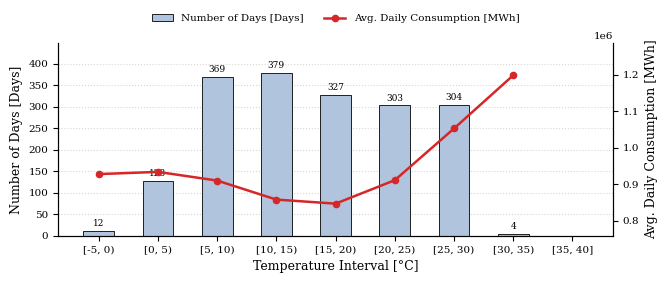

In [21]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ==========================================================
# 1. Cấu hình Matplotlib chuẩn bài báo khoa học (LaTeX/PDF)
# ==========================================================
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["font.family"] = "serif"
mpl.rcParams["font.size"] = 8  # Base font size: 8 pt
mpl.rcParams["text.color"] = "black"
mpl.rcParams["axes.labelcolor"] = "black"
mpl.rcParams["xtick.color"] = "black"
mpl.rcParams["ytick.color"] = "black"

# ==========================================================
# 2. Xử lý dữ liệu & Phân khoảng nhiệt độ (-5°C đến 40°C)
# ==========================================================
years = [2021, 2022, 2023, 2024, 2025]
df_sub = E[E["year"].isin(years)].copy()

# Bước 1: Tổng hợp dữ liệu cấp ngày
daily_df = (
    df_sub.groupby(df_sub["time"].dt.date)
    .agg(
        daily_consumption=("consumption", "sum"),
        daily_temp=("temperature", "mean"),
    )
    .reset_index()
)

# Bước 2: Thiết lập 9 khoảng nhiệt độ 5°C từ -5 đến 40°C
bins = [-5, 0, 5, 10, 15, 20, 25, 30, 35, 40]
bin_labels = [
    "[-5, 0)",
    "[0, 5)",
    "[5, 10)",
    "[10, 15)",
    "[15, 20)",
    "[20, 25)",
    "[25, 30)",
    "[30, 35)",
    "[35, 40]",
]

daily_filtered = daily_df[
    (daily_df["daily_temp"] >= -5) & (daily_df["daily_temp"] <= 40)
].copy()

daily_filtered["temp_bin"] = pd.cut(
    daily_filtered["daily_temp"],
    bins=bins,
    labels=bin_labels,
    right=False,
    include_lowest=True,
)

# Bước 3: Tính số lượng ngày và lượng tiêu thụ trung bình ngày
summary_df = (
    daily_filtered.groupby("temp_bin", observed=False)
    .agg(
        day_count=("daily_consumption", "count"),
        avg_daily_consumption=("daily_consumption", "mean"),
    )
    .reset_index()
)

# ==========================================================
# 3. Vẽ biểu đồ song trục (Dual-Axis Plot)
# ==========================================================
# Khổ chuẩn bài báo 2 cột: ngang 7.16 in, cao 2.5 in
fig, ax1 = plt.subplots(figsize=(7.16, 2.5))

x = np.arange(len(bin_labels))
width = 0.52

# Trục Y1 (Trái): Cột biểu diễn Số lượng ngày
bars = ax1.bar(
    x,
    summary_df["day_count"],
    width=width,
    color="#B0C4DE",
    edgecolor="black",
    linewidth=0.6,
    label="Number of Days [Days]",
    zorder=2,
)

# Hiển thị số ngày trực tiếp trên đỉnh cột (chỉ hiện khi có ngày xuất hiện)
for bar in bars:
    height = bar.get_height()
    if height > 0:
        ax1.annotate(
            f"{int(height)}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 2),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=6.5,
            color="black",
        )

ax1.set_xlabel("Temperature Interval [°C]", fontsize=9, color="black")
ax1.set_ylabel("Number of Days [Days]", fontsize=9, color="black")
ax1.tick_params(axis="both", labelsize=7.5)
ax1.set_xticks(x)
ax1.set_xticklabels(bin_labels, fontsize=7.5)

# Giới hạn trục Y1 mở rộng nhẹ đỉnh
max_days = summary_df["day_count"].max()
ax1.set_ylim(0, max_days * 1.18 if max_days > 0 else 10)
ax1.grid(axis="y", linestyle=":", alpha=0.5, zorder=1)

# Trục Y2 (Phải): Đường biểu diễn Consumption trung bình ngày
ax2 = ax1.twinx()

# Lọc các điểm có dữ liệu để vẽ đường không bị gián đoạn hoặc lỗi NaN
valid_mask = summary_df["day_count"] > 0
x_valid = x[valid_mask]
y_valid = summary_df.loc[valid_mask, "avg_daily_consumption"]

line = ax2.plot(
    x_valid,
    y_valid,
    color="#D62728",
    linewidth=1.8,
    marker="o",
    markersize=4.5,
    label="Avg. Daily Consumption [MWh]",
    zorder=4,
)

ax2.set_ylabel("Avg. Daily Consumption [MWh]", fontsize=9, color="black")
ax2.tick_params(axis="y", labelcolor="black", labelsize=7.5)
ax2.yaxis.get_offset_text().set_fontsize(7.5)
ax2.yaxis.get_offset_text().set_color("black")

# Giới hạn trục Y2 bám sát đường cong chữ U thực tế
if not y_valid.empty:
    c_min = y_valid.min()
    c_max = y_valid.max()
    span = c_max - c_min if c_max != c_min else 1.0
    ax2.set_ylim(c_min - 0.25 * span, c_max + 0.25 * span)

# ==========================================================
# 4. Gộp Chú giải (Legend) thống nhất đặt phía trên đỉnh
# ==========================================================
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

legend = ax1.legend(
    handles=handles1 + handles2,
    labels=labels1 + labels2,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.20),
    ncol=2,
    frameon=False,
    fontsize=7.5,
)

for text in legend.get_texts():
    text.set_color("black")

# Lược bỏ viền trên
ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

# ==========================================================
# 5. Xuất file PDF vector tối ưu lề cho LaTeX
# ==========================================================
plt.savefig(
    "dual_axis_temp_bins_extended_5years.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.02,
)

plt.show()

In [33]:
# import matplotlib as mpl
# import matplotlib.pyplot as plt
# import numpy as np
# import pandas as pd
# import seaborn as sns

# # ==========================================================
# # 1. Cấu hình Matplotlib chuẩn bài báo khoa học (LaTeX/PDF)
# # ==========================================================
# mpl.rcParams["pdf.fonttype"] = 42
# mpl.rcParams["ps.fonttype"] = 42
# mpl.rcParams["font.family"] = "serif"
# mpl.rcParams["font.size"] = 8  # Base font size: 8 pt
# mpl.rcParams["text.color"] = "black"
# mpl.rcParams["axes.labelcolor"] = "black"
# mpl.rcParams["xtick.color"] = "black"
# mpl.rcParams["ytick.color"] = "black"

# # ==========================================================
# # 2. Xử lý dữ liệu cấp giờ & Phân khoảng nhiệt độ (-5°C đến 40°C)
# # ==========================================================
# years = [2021, 2022, 2023, 2024, 2025]
# df_hourly = E[E["year"].isin(years)].copy()

# # Lọc các dòng có nhiệt độ trong khoảng [-5, 40]
# bins = [-5, 0, 5, 10, 15, 20, 25, 30, 35, 40]
# bin_labels = [
#     "[-5, 0)",
#     "[0, 5)",
#     "[5, 10)",
#     "[10, 15)",
#     "[15, 20)",
#     "[20, 25)",
#     "[25, 30)",
#     "[30, 35)",
#     "[35, 40]",
# ]

# df_hourly = df_hourly[
#     (df_hourly["temperature"] >= -5) & (df_hourly["temperature"] <= 40)
# ].copy()

# # Phân loại khoảng nhiệt độ trực tiếp theo từng giờ
# df_hourly["temp_bin"] = pd.cut(
#     df_hourly["temperature"],
#     bins=bins,
#     labels=bin_labels,
#     right=False,
#     include_lowest=True,
# )

# # Tổng hợp: đếm số giờ và tính mức tiêu thụ trung bình giờ cho từng bin
# summary_hourly = (
#     df_hourly.groupby("temp_bin", observed=False)
#     .agg(
#         hour_count=("consumption", "count"),
#         avg_hourly_consumption=("consumption", "mean"),
#     )
#     .reset_index()
# )

# # ==========================================================
# # 3. Vẽ biểu đồ song trục cấp giờ (Dual-Axis Hourly Plot)
# # ==========================================================
# # Khổ chuẩn bài báo 2 cột: ngang 7.16 in, cao 2.5 in
# fig, ax1 = plt.subplots(figsize=(7.16, 2.5))

# x = np.arange(len(bin_labels))
# width = 0.52

# # Trục Y1 (Trái): Cột biểu diễn Số lượng giờ
# bars = ax1.bar(
#     x,
#     summary_hourly["hour_count"],
#     width=width,
#     color="#B0C4DE",
#     edgecolor="black",
#     linewidth=0.6,
#     label="Number of Hours [Hours]",
#     zorder=2,
# )

# # Hiển thị số giờ trực tiếp trên đỉnh cột
# for bar in bars:
#     height = bar.get_height()
#     if height > 0:
#         ax1.annotate(
#             f"{int(height)}",
#             xy=(bar.get_x() + bar.get_width() / 2, height),
#             xytext=(0, 2),
#             textcoords="offset points",
#             ha="center",
#             va="bottom",
#             fontsize=6.5,
#             color="black",
#         )

# ax1.set_xlabel("Temperature Interval [°C]", fontsize=9, color="black")
# ax1.set_ylabel("Number of Hours [Hours]", fontsize=9, color="black")
# ax1.tick_params(axis="both", labelsize=7.5)
# ax1.set_xticks(x)
# ax1.set_xticklabels(bin_labels, fontsize=7.5)

# # Giới hạn trục Y1 mở rộng nhẹ đỉnh để không bị cấn số liệu
# max_hours = summary_hourly["hour_count"].max()
# ax1.set_ylim(0, max_hours * 1.18 if max_hours > 0 else 10)
# ax1.grid(axis="y", linestyle=":", alpha=0.5, zorder=1)

# # Trục Y2 (Phải): Đường biểu diễn Consumption trung bình giờ
# ax2 = ax1.twinx()

# # Lọc các bin có dữ liệu thực tế
# valid_mask = summary_hourly["hour_count"] > 0
# x_valid = x[valid_mask]
# y_valid = summary_hourly.loc[valid_mask, "avg_hourly_consumption"]

# line = ax2.plot(
#     x_valid,
#     y_valid,
#     color="#D62728",
#     linewidth=1.8,
#     marker="o",
#     markersize=4.5,
#     label="Avg. Hourly Consumption [MWh]",
#     zorder=4,
# )

# ax2.set_ylabel(
#     "Avg. Hourly Consumption [MWh]", fontsize=9, color="black"
# )
# ax2.tick_params(axis="y", labelcolor="black", labelsize=7.5)
# ax2.yaxis.get_offset_text().set_fontsize(7.5)
# ax2.yaxis.get_offset_text().set_color("black")

# # Giới hạn trục Y2 bám sát biên độ tiêu thụ cấp giờ
# if not y_valid.empty:
#     c_min = y_valid.min()
#     c_max = y_valid.max()
#     span = c_max - c_min if c_max != c_min else 1.0
#     ax2.set_ylim(c_min - 0.25 * span, c_max + 0.25 * span)

# # ==========================================================
# # 4. Gộp Chú giải (Legend) thống nhất đặt phía trên đỉnh
# # ==========================================================
# handles1, labels1 = ax1.get_legend_handles_labels()
# handles2, labels2 = ax2.get_legend_handles_labels()

# legend = ax1.legend(
#     handles=handles1 + handles2,
#     labels=labels1 + labels2,
#     loc="upper center",
#     bbox_to_anchor=(0.5, 1.20),
#     ncol=2,
#     frameon=False,
#     fontsize=7.5,
# )

# for text in legend.get_texts():
#     text.set_color("black")

# # Lược bỏ viền trên
# ax1.spines["top"].set_visible(False)
# ax2.spines["top"].set_visible(False)

# # ==========================================================
# # 5. Xuất file PDF vector tối ưu lề cho LaTeX
# # ==========================================================
# plt.savefig(
#     "dual_axis_temp_bins_hours_and_consumption.pdf",
#     format="pdf",
#     bbox_inches="tight",
#     pad_inches=0.02,
# )

# plt.show()

In [35]:
# import matplotlib as mpl
# import matplotlib.pyplot as plt
# import numpy as np
# import pandas as pd
# import seaborn as sns

# # ==========================================================
# # 1. Cấu hình Matplotlib chuẩn bài báo khoa học (LaTeX/PDF)
# # ==========================================================
# mpl.rcParams["pdf.fonttype"] = 42
# mpl.rcParams["ps.fonttype"] = 42
# mpl.rcParams["font.family"] = "serif"
# mpl.rcParams["font.size"] = 8  # Base font size: 8 pt
# mpl.rcParams["text.color"] = "black"
# mpl.rcParams["axes.labelcolor"] = "black"
# mpl.rcParams["xtick.color"] = "black"
# mpl.rcParams["ytick.color"] = "black"

# # ==========================================================
# # 2. Xử lý dữ liệu đa năm (2021 - 2025)
# # ==========================================================
# years = [2021, 2022, 2023, 2024, 2025]
# df_multi = E[E["year"].isin(years)].copy()

# # Thang giá trị nhiệt độ đồng nhất cho cả 5 năm
# vmin = df_multi["temperature"].min()
# vmax = df_multi["temperature"].max()

# # ==========================================================
# # 3. Khởi tạo Subplots (5 hàng x 1 cột)
# # ==========================================================
# num_years = len(years)
# fig_height = 1.7 * num_years

# fig, axes = plt.subplots(
#     nrows=num_years,
#     ncols=1,
#     figsize=(7.16, fig_height),
#     sharex=False,
#     gridspec_kw={"hspace": 0.35},
# )

# # Chừa lề phải cho Colorbar độc lập
# plt.subplots_adjust(left=0.09, right=0.88, top=0.96, bottom=0.06)

# # Mốc ngày giữa tháng chuẩn để gióng thẳng trục hoành giữa các năm
# mid_month_days = [15, 45, 74, 105, 135, 166, 196, 227, 258, 288, 319, 349]
# month_labels = [
#     "Jan",
#     "Feb",
#     "Mar",
#     "Apr",
#     "May",
#     "Jun",
#     "Jul",
#     "Aug",
#     "Sep",
#     "Oct",
#     "Nov",
#     "Dec",
# ]

# # Các mốc giờ cần hiển thị trên trục tung
# hour_ticks = [0, 6, 12, 18, 23]
# tick_positions = [23.5 - h for h in hour_ticks]

# for idx, year in enumerate(years):
#     ax = axes[idx]
#     df_year = df_multi[df_multi["year"] == year].copy()

#     df_year["day_of_year"] = df_year["time"].dt.dayofyear

#     # Pivot table: Hàng là Hour (0 - 23), Cột là Day of Year (1 - 365/366)
#     heatmap_matrix = df_year.pivot(
#         index="hour", columns="day_of_year", values="temperature"
#     )

#     # Đảo thứ tự để 0:00 ở đáy, 23:00 ở đỉnh; mở rộng cột đến 366 ngày
#     heatmap_matrix = heatmap_matrix.reindex(
#         index=range(23, -1, -1), columns=range(1, 367)
#     )

#     sns.heatmap(
#         heatmap_matrix,
#         cmap="coolwarm",
#         vmin=vmin,
#         vmax=vmax,
#         cbar=False,
#         rasterized=True,  # Tối ưu dung lượng vector PDF
#         ax=ax,
#     )

#     # Trục tung: 24 giờ
#     ax.set_yticks(tick_positions)
#     ax.set_yticklabels([f"{h:02d}:00" for h in hour_ticks], fontsize=7)
#     ax.set_ylabel(f"{year}\nHour", fontsize=8, color="black")

#     # Trục hoành: 12 tháng
#     ax.set_xlim(0, 366)
#     ax.set_xticks(mid_month_days)

#     if idx == num_years - 1:
#         ax.set_xticklabels(month_labels, fontsize=8)
#         ax.set_xlabel("Month of Year", fontsize=9, color="black")
#     else:
#         ax.set_xticklabels([])
#         ax.set_xlabel("")

# # ==========================================================
# # 4. Tạo Colorbar riêng biệt bao quát toàn bộ 5 năm
# # ==========================================================
# cbar_ax = fig.add_axes([0.91, 0.25, 0.018, 0.50])
# norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
# sm = plt.cm.ScalarMappable(cmap="coolwarm", norm=norm)
# sm.set_array([])

# cbar = fig.colorbar(sm, cax=cbar_ax)
# cbar.ax.tick_params(labelsize=7.5, colors="black")
# cbar.ax.set_title("[°C]", fontsize=8, pad=6, loc="center", color="black")

# # ==========================================================
# # 5. Xuất file PDF vector tối ưu lề cho LaTeX
# # ==========================================================
# plt.savefig(
#     "heatmap_hourly_temperature_5years.pdf",
#     format="pdf",
#     bbox_inches="tight",
#     pad_inches=0.02,
# )

# plt.show()

In [32]:
# import matplotlib as mpl
# import matplotlib.pyplot as plt
# import numpy as np
# import pandas as pd
# import seaborn as sns

# # ==========================================================
# # 1. Cấu hình Matplotlib chuẩn bài báo khoa học (LaTeX/PDF)
# # ==========================================================
# mpl.rcParams["pdf.fonttype"] = 42
# mpl.rcParams["ps.fonttype"] = 42
# mpl.rcParams["font.family"] = "serif"
# mpl.rcParams["font.size"] = 8  # Base font size: 8 pt
# mpl.rcParams["text.color"] = "black"
# mpl.rcParams["axes.labelcolor"] = "black"
# mpl.rcParams["xtick.color"] = "black"
# mpl.rcParams["ytick.color"] = "black"

# # ==========================================================
# # 2. Xử lý dữ liệu cấp ngày theo từng năm (2021 - 2025)
# # ==========================================================
# years = [2021, 2022, 2023, 2024, 2025]
# df_sub = E[E["year"].isin(years)].copy()

# daily_df = (
#     df_sub.groupby([df_sub["time"].dt.date, "year"])
#     .agg(
#         daily_consumption=("consumption", "sum"),
#         daily_temp=("temperature", "mean"),
#     )
#     .reset_index()
# )

# # ==========================================================
# # 3. Vẽ 5 Subplots tán xạ (1 hàng x 5 cột)
# # ==========================================================
# # Khổ chuẩn bài báo 2 cột: ngang 7.16 in, cao 2.2 in (~ tỷ lệ 3.25 : 1)
# fig, axes = plt.subplots(
#     nrows=1,
#     ncols=5,
#     figsize=(7.16, 2.2),
#     sharey=True,
#     gridspec_kw={"wspace": 0.12},
# )

# # Xác định biên nhiệt độ chung cho trục hoành
# t_min = np.floor(daily_df["daily_temp"].min() / 5) * 5
# t_max = np.ceil(daily_df["daily_temp"].max() / 5) * 5
# x_vals = np.linspace(t_min, t_max, 100)

# for idx, year in enumerate(years):
#     ax = axes[idx]
#     data_yr = daily_df[daily_df["year"] == year].dropna(
#         subset=["daily_temp", "daily_consumption"]
#     )

#     # 1. Điểm tán xạ (Scatter points)
#     ax.scatter(
#         data_yr["daily_temp"],
#         data_yr["daily_consumption"],
#         color="#4A90E2",
#         alpha=0.45,
#         s=10,
#         edgecolors="none",
#         rasterized=True,  # Giảm dung lượng vector PDF
#         label="Daily Observation",
#     )

#     # 2. Đường hồi quy đa thức bậc 2 (Quadratic Fit)
#     if len(data_yr) > 2:
#         poly_coeffs = np.polyfit(
#             data_yr["daily_temp"], data_yr["daily_consumption"], deg=2
#         )
#         y_fit = np.polyval(poly_coeffs, x_vals)
#         ax.plot(
#             x_vals,
#             y_fit,
#             color="#D62728",
#             linewidth=1.4,
#             linestyle="-",
#             label="Quadratic Fit",
#         )

#     # Đánh nhãn năm ở góc trên bên trái từng subplot
#     ax.text(
#         0.08,
#         0.90,
#         f"{year}",
#         transform=ax.transAxes,
#         fontsize=8,
#         fontweight="bold",
#         color="black",
#         va="top",
#     )

#     # Tinh chỉnh trục hoành
#     ax.set_xlim(t_min, t_max)
#     ax.set_xticks(np.arange(t_min, t_max + 1, 10))
#     ax.tick_params(axis="both", labelsize=7)
#     ax.grid(True, linestyle=":", alpha=0.5)
#     sns.despine(ax=ax)

# # ==========================================================
# # 4. Tinh chỉnh Nhãn trục & Legend chung
# # ==========================================================
# # Nhãn trục tung chỉ hiển thị ở biểu đồ đầu tiên
# axes[0].set_ylabel("Daily Consumption [MWh]", fontsize=9, color="black")
# axes[0].yaxis.get_offset_text().set_fontsize(7)

# # Nhãn trục hoành đặt ở vị trí trung tâm phía dưới
# fig.text(
#     0.5,
#     0.02,
#     "Daily Mean Temperature [°C]",
#     ha="center",
#     fontsize=9,
#     color="black",
# )

# # Chú giải chung đặt phía trên đỉnh
# handles, labels = axes[0].get_legend_handles_labels()
# legend = fig.legend(
#     handles,
#     labels,
#     loc="upper center",
#     bbox_to_anchor=(0.5, 1.15),
#     ncol=2,
#     frameon=False,
#     fontsize=7.5,
# )
# for text in legend.get_texts():
#     text.set_color("black")

# plt.subplots_adjust(top=0.88, bottom=0.22, left=0.09, right=0.98)

# # ==========================================================
# # 5. Xuất file PDF vector tối ưu lề cho LaTeX
# # ==========================================================
# plt.savefig(
#     "scatter_daily_consumption_temp_5years.pdf",
#     format="pdf",
#     bbox_inches="tight",
#     pad_inches=0.02,
# )

# plt.show()

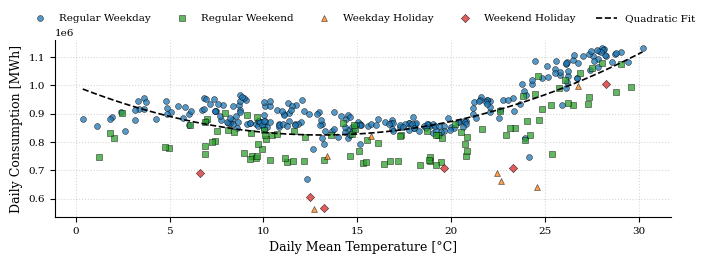

In [31]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ==========================================================
# 1. Cấu hình Matplotlib chuẩn bài báo khoa học (LaTeX/PDF)
# ==========================================================
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["font.family"] = "serif"
mpl.rcParams["font.size"] = 8  # Base font size: 8 pt
mpl.rcParams["text.color"] = "black"
mpl.rcParams["axes.labelcolor"] = "black"
mpl.rcParams["xtick.color"] = "black"
mpl.rcParams["ytick.color"] = "black"

# ==========================================================
# 2. Xử lý dữ liệu cấp ngày năm 2023 & Phân loại 4 nhóm ngày
# ==========================================================
df_2023 = E[E["year"] == 2023].copy()


def classify_day_type(row):
    if row["holiday"] == 1 and row["weekend"] == 1:
        return "Weekend Holiday"
    elif row["holiday"] == 1 and row["weekend"] == 0:
        return "Weekday Holiday"
    elif row["holiday"] == 0 and row["weekend"] == 1:
        return "Regular Weekend"
    else:
        return "Regular Weekday"


daily_2023 = (
    df_2023.groupby(df_2023["time"].dt.date)
    .agg(
        daily_consumption=("consumption", "sum"),
        daily_temp=("temperature", "mean"),
        holiday=("holiday", "max"),
        weekend=("weekend", "max"),
    )
    .dropna(subset=["daily_consumption", "daily_temp"])
    .reset_index()
)

daily_2023["day_type"] = daily_2023.apply(classify_day_type, axis=1)

# Thứ tự, bảng màu và marker đồng bộ
day_types = [
    "Regular Weekday",
    "Regular Weekend",
    "Weekday Holiday",
    "Weekend Holiday",
]

palette = {
    "Regular Weekday": "#1f77b4",  # Xanh dương
    "Regular Weekend": "#2ca02c",  # Xanh lá cây
    "Weekday Holiday": "#ff7f0e",  # Cam
    "Weekend Holiday": "#d62728",  # Đỏ
}

markers = {
    "Regular Weekday": "o",
    "Regular Weekend": "s",
    "Weekday Holiday": "^",
    "Weekend Holiday": "D",
}

# ==========================================================
# 3. Vẽ Scatter Plot với tỷ lệ dẹt ngang (Panoramic Layout)
# ==========================================================
# Khổ chuẩn bài báo 2 cột: ngang 7.16 in, cao 2.6 in (~ tỷ lệ 2.75 : 1)
fig, ax = plt.subplots(figsize=(7.16, 2.6))

# 1. Vẽ các điểm tán xạ theo từng loại ngày
for dt in day_types:
    sub = daily_2023[daily_2023["day_type"] == dt]
    if not sub.empty:
        ax.scatter(
            sub["daily_temp"],
            sub["daily_consumption"],
            label=dt,
            color=palette[dt],
            marker=markers[dt],
            s=18,
            alpha=0.75,
            edgecolors="black",
            linewidth=0.4,
            rasterized=True,  # Giảm dung lượng file PDF
            zorder=3,
        )

# 2. Đường hồi quy phi tuyến bậc 2 tổng thể (Quadratic Fit)
t_min = daily_2023["daily_temp"].min()
t_max = daily_2023["daily_temp"].max()
x_fit = np.linspace(t_min, t_max, 150)

poly_coeffs = np.polyfit(
    daily_2023["daily_temp"], daily_2023["daily_consumption"], deg=2
)
y_fit = np.polyval(poly_coeffs, x_fit)

ax.plot(
    x_fit,
    y_fit,
    color="black",
    linewidth=1.2,
    linestyle="--",
    label="Quadratic Fit",
    zorder=4,
)

# ==========================================================
# 4. Tinh chỉnh trục & Nhãn (Font size chuẩn 6.5 - 9 pt)
# ==========================================================
ax.set_xlabel("Daily Mean Temperature [°C]", fontsize=9, color="black")
ax.set_ylabel("Daily Consumption [MWh]", fontsize=9, color="black")
ax.tick_params(axis="both", labelsize=7.5)
ax.yaxis.get_offset_text().set_fontsize(7.5)

sns.despine(ax=ax)
ax.grid(True, linestyle=":", alpha=0.5, zorder=1)

# Chú giải (Legend) dạng hàng ngang đặt phía trên đỉnh
legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.20),
    ncol=5,
    frameon=False,
    fontsize=7.5,
)
for text in legend.get_texts():
    text.set_color("black")

plt.subplots_adjust(top=0.86, bottom=0.18, left=0.10, right=0.96)

# ==========================================================
# 5. Xuất file PDF vector tối ưu lề cho LaTeX
# ==========================================================
plt.savefig(
    "scatter_daily_consumption_temp_2023_4daytypes.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.02,
)

plt.show()